# Notebook 3 — Why the Scan Matters (parallelizing a "sequential" recurrence)

**Goal:** implement the affine recurrence $h_t = a_t h_{t-1} + b_t$ two ways — a naive sequential Python loop, and a **parallel associative scan** — verify they give identical results, then benchmark the difference.

This is the piece that makes selective SSMs practical: Notebook 2's selective recurrence *cannot* be written as a fixed convolution (unlike Notebook 1's system), so Mamba needs a different trick to avoid an $O(L)$ sequential loop on the GPU. That trick is a parallel scan.

In [1]:
import torch
import time
import matplotlib.pyplot as plt

torch.manual_seed(0)

## 1. The recurrence is associative

Consider the affine map $h \mapsto a\,h + b$, represented as a pair $(a, b)$. Composing two such maps — apply $(a_1, b_1)$, then $(a_2, b_2)$ — gives another affine map:

$$
(a_1, b_1) \oplus (a_2, b_2) = (a_1 a_2,\; a_2 b_1 + b_2)
$$

This composition operator $\oplus$ is **associative** (though not commutative): $(p \oplus q) \oplus r = p \oplus (q \oplus r)$. Associativity is exactly the property that lets a *sequential-looking* computation be reorganized into a *tree* — combine adjacent pairs, then adjacent pairs-of-pairs, and so on — for $O(\log L)$ parallel depth instead of $O(L)$ sequential depth. This is a classical parallel-prefix-sum ("scan") technique from parallel computing, and it's the mechanism Mamba's CUDA kernel implements (fused, and considerably more optimized than what we'll write here in plain PyTorch).

## 2. Sequential scan (the naive, obviously-correct version)

In [2]:
def sequential_scan(a, b, h0):
    """a, b: (batch, L) ; h0: (batch,) -> returns h: (batch, L)"""
    B, L = a.shape
    h = h0
    hs = []
    for t in range(L):
        h = a[:, t] * h + b[:, t]
        hs.append(h)
    return torch.stack(hs, dim=1)

## 3. Parallel (log-depth) scan

We implement the classic "doubling" scan: at each round, combine every element with the element $2^k$ positions before it (using the identity element $(a{=}1, b{=}0)$ where there's nothing to combine with). After $\lceil \log_2 L \rceil$ rounds, every position holds the cumulative combination of everything before it.

In [3]:
def combine(pair1, pair2):
    a1, b1 = pair1
    a2, b2 = pair2
    return a1 * a2, a2 * b1 + b2

def parallel_scan(a, b, h0):
    """Log-depth inclusive scan of the affine operator, matching sequential_scan exactly."""
    Bsz, L = a.shape
    # fold h0 in as an extra 'step -1': (a=0, b=h0)
    a_full = torch.cat([torch.zeros(Bsz, 1), a], dim=1)
    b_full = torch.cat([h0.unsqueeze(1), b], dim=1)

    n = a_full.shape[1]
    log2n = (n - 1).bit_length()
    padded_n = 1 << log2n
    pad = padded_n - n
    if pad > 0:
        a_full = torch.cat([a_full, torch.ones(Bsz, pad)], dim=1)
        b_full = torch.cat([b_full, torch.zeros(Bsz, pad)], dim=1)

    a_cur, b_cur = a_full.clone(), b_full.clone()
    step = 1
    while step < padded_n:
        a_shifted = torch.cat([torch.ones(Bsz, step), a_cur[:, :-step]], dim=1)
        b_shifted = torch.cat([torch.zeros(Bsz, step), b_cur[:, :-step]], dim=1)
        a_cur, b_cur = combine((a_shifted, b_shifted), (a_cur, b_cur))
        step *= 2

    return b_cur[:, 1:n]  # drop the h0 slot; states h_0..h_{L-1} remain

## 4. Correctness check

Both implementations should agree to numerical precision, on a sequence length that isn't even a power of two (to make sure padding is handled correctly).

In [4]:
Bsz, L = 4, 37  # deliberately not a power of 2
a = torch.rand(Bsz, L) * 0.6 + 0.2
b = torch.randn(Bsz, L) * 0.1
h0 = torch.randn(Bsz)

h_seq = sequential_scan(a, b, h0)
h_par = parallel_scan(a, b, h0)

max_err = (h_seq - h_par).abs().max().item()
print(f"max abs error, sequential vs parallel scan: {max_err:.2e}")
assert max_err < 1e-4
print("OK: parallel scan matches sequential scan exactly.")

max abs error, sequential vs parallel scan: 5.96e-08
OK: parallel scan matches sequential scan exactly.


## 5. Benchmark

The sequential scan does $O(L)$ *dependent* Python-level steps — each one waits for the last. The parallel scan does $O(\log L)$ rounds, each a single batched tensor op. On CPU (a single core, mostly) the win comes purely from fewer, larger vectorized ops rather than from true hardware parallelism, but the trend is the same trend that makes Mamba's fused GPU scan dramatically faster than a naive loop at long sequence lengths.

L=   128 | sequential 0.00112s | parallel 0.00024s
L=   512 | sequential 0.00455s | parallel 0.00041s
L=  2048 | sequential 0.01782s | parallel 0.00098s


L=  8192 | sequential 0.07138s | parallel 0.00580s


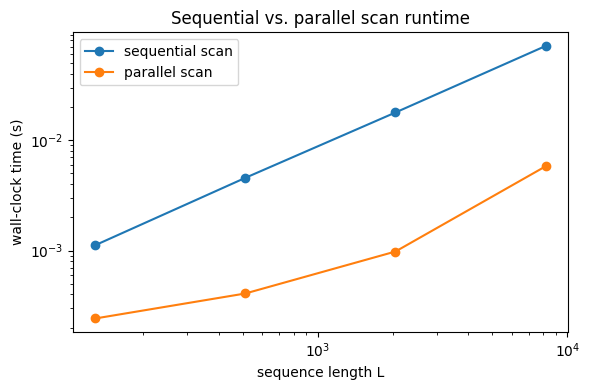

In [5]:
def bench(fn, a, b, h0, n_repeat=5):
    fn(a, b, h0)  # warmup
    t0 = time.time()
    for _ in range(n_repeat):
        fn(a, b, h0)
    return (time.time() - t0) / n_repeat

lengths = [128, 512, 2048, 8192]
seq_times, par_times = [], []
for L_test in lengths:
    a = torch.rand(8, L_test) * 0.6 + 0.2
    b = torch.randn(8, L_test) * 0.1
    h0 = torch.randn(8)
    seq_times.append(bench(sequential_scan, a, b, h0))
    par_times.append(bench(parallel_scan, a, b, h0))
    print(f"L={L_test:6d} | sequential {seq_times[-1]:.5f}s | parallel {par_times[-1]:.5f}s")

plt.figure(figsize=(6, 4))
plt.plot(lengths, seq_times, "o-", label="sequential scan")
plt.plot(lengths, par_times, "o-", label="parallel scan")
plt.xlabel("sequence length L")
plt.ylabel("wall-clock time (s)")
plt.xscale("log")
plt.yscale("log")
plt.title("Sequential vs. parallel scan runtime")
plt.legend()
plt.tight_layout()
plt.show()

## Exercise

1. The gap between sequential and parallel scan grows with `L`. Fit a rough scaling law to `seq_times` and `par_times` (e.g. plot on log-log axes) — does it look closer to $O(L)$ vs $O(\log L)$, or something else? What might cause deviations on CPU?
2. Modify `sequential_scan` and `parallel_scan` to operate on **state_dim > 1** (i.e. `a, b` of shape `(batch, L, state_dim)` instead of `(batch, L)`), and re-check correctness. This is the shape actually used by the SelectiveSSM in Notebook 2.
3. (Optional, needs a GPU) Move `a, b, h0` to `"cuda"` and re-run the benchmark — how much does the parallel scan's advantage change with real hardware parallelism?